In [3]:
%run ./functions.ipynb

In [5]:
import matplotlib.pyplot as plt

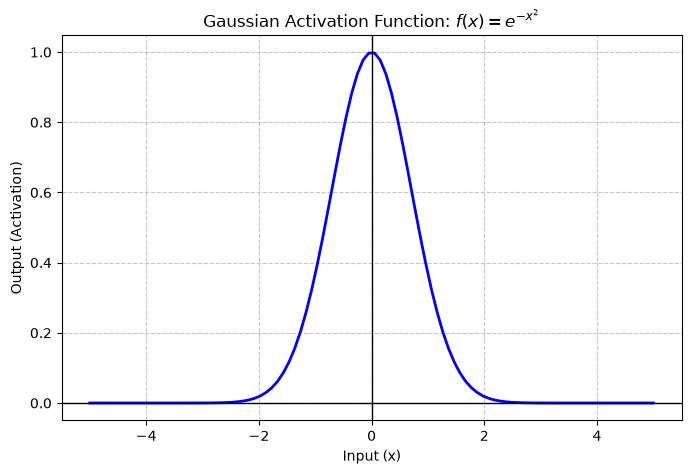

All numerical tests passed successfully!


In [14]:
gauss_act = GaussianActivation()

#plot
#generate domain
x_vals = torch.linspace(-5, 5, 100)

# Pass the points through the activation function
y_vals = gauss_act(x_vals)

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(x_vals.numpy(), y_vals.numpy(), linewidth=2, color='blue')
plt.title("Gaussian Activation Function: $f(x) = e^{-x^2}$")
plt.xlabel("Input (x)")
plt.ylabel("Output (Activation)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.show()

# test, peak at x = 0 should be 1.0 (e^0 = 1)
assert torch.allclose(gauss_act(torch.tensor([0.0])), torch.tensor([1.0])), "Failed: Peak should be 1 at x=0"

# test symmetry (f(x) should equal f(-x))
N_tp=3
val_pos = [gauss_act(torch.tensor([i + 0.1])) for i in range(N_tp)]
val_neg = [gauss_act(torch.tensor([-i - 0.1])) for i in range(N_tp)]
for i in range(N_tp):
    assert torch.allclose(val_pos[i], val_neg[i]), "Failed: Function is not symmetric"

# test verify a specific value (x = 1 should output e^-1, approx 0.3678)
expected_val = torch.exp(torch.tensor([-1.0]))
assert torch.allclose(gauss_act(torch.tensor([1.0])), expected_val), "Failed: Incorrect calculation at x=1"

print("All numerical tests passed successfully!")

In [15]:
# test gradient
x_grad_test = torch.tensor([1.0, -0.5], requires_grad=True)

# forward pass
y_grad_test = gauss_act(x_grad_test)

# backward pass (sum is used to create a scalar for .backward())
y_grad_test.sum().backward()

# calculate the expected gradients mathematically
expected_grad = -2.0 * x_grad_test * torch.exp(-torch.pow(x_grad_test, 2))

# compare autograd result with the mathematical expectation
assert torch.allclose(x_grad_test.grad, expected_grad), "Failed: Gradients do not match expected mathematical derivative"

In [24]:
import torch.nn.functional as F
from torch.distributions import Categorical

%run ./functions.ipynb
%run ./nnFornnHP.ipynb

# initialize controller
pos_len = [2, 3]
pos_size = [4, 8]
controller = HyperparameterController(pos_len, pos_size)

print("Running LSTM Controller Validation Tests...\n")

params, log_prob, entropy = controller.sample_hyperparameters(temperature=1.0)

print(f"Sampled Params: {params}")
# layer_sizes and num_layers should be equal
assert len(params['layer_sizes']) == params['num_layers'], "Failed: Length of layer_sizes does not match num_layers"
# activation and value in map should be equal, same with learning rate
assert params['activation'] in controller.act_map.values(), "Failed: Invalid activation sampled"
assert params['learning_rate'] in controller.lr_map.values(), "Failed: Invalid learning rate sampled"

print("✓ Structure and Dynamic Loop: PASSED")

# ensure loss calculation reaches the LSTM weights
optimizer = torch.optim.Adam(controller.parameters(), lr=0.01)
optimizer.zero_grad()

# mock a positive advantage (the model did better than the baseline)
mock_advantage = torch.tensor([1.5])

# calculate loss using gradient formula
loss = (-log_prob * mock_advantage) - (0.05 * entropy)
loss.backward()

# check gradients have successfully populated the network
assert controller.act_head.weight.grad is not None, "Failed: No gradient at Activation Head"
assert controller.lstm.weight_ih.grad is not None, "Failed: No gradient at LSTM Cell"
assert controller.embedding.weight.grad is not None, "Failed: No gradient at Embedding Layer"

# ensure gradients are not just zeros
assert torch.sum(torch.abs(controller.lstm.weight_ih.grad)) > 0, "Failed: LSTM gradients are zero"

optimizer.step()
print("✓ Gradient Flow (REINFORCE Algorithm): PASSED")

# high temperature should flatten distribution, resulting in higher entropy, dS = dQ/T ~ dT/T, S -> ~log(T)
_, _, high_entropy = controller.sample_hyperparameters(temperature=5.0)

# low temperature, sharp distribution, low entropy
_, _, low_entropy = controller.sample_hyperparameters(temperature=0.1)

assert high_entropy.item() > low_entropy.item(), "Failed: Temperature scaling is not affecting entropy correctly"

print(f"  High Temp Entropy: {high_entropy.item():.4f}")
print(f"  Low Temp Entropy:  {low_entropy.item():.4f}")
print("✓ Temperature Scaling: PASSED")
print("\nAll LSTM Controller tests passed")

Running LSTM Controller Validation Tests...

Sampled Params: {'activation': 'softmax', 'learning_rate': 1.0, 'num_layers': 2, 'layer_sizes': [4, 4]}
✓ Structure and Dynamic Loop: PASSED
✓ Gradient Flow (REINFORCE Algorithm): PASSED
  High Temp Entropy: 5.5444
  Low Temp Entropy:  4.2020
✓ Temperature Scaling: PASSED

All LSTM Controller tests passed
